In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

from pathlib import Path

In [2]:
data_path = Path("../data/raw/manufacturing_data.csv")

df = pd.read_csv(data_path)

df.head()

,Machine_ID,Timestamp,Machine_Type,Machine_Age_Years,Operating_Hours,Temperature_C,Vibration_mm_s,Pressure_bar,Motor_Current_A,Production_Count,Production_Rate,Last_Maintenance_Days,Maintenance_Count,Failure_Count,Failure_Next_30_Days,Failure_Type
0,M052,2025-01-01 00:00:00,Grinding,15,33059,86.051980,6.004030,7.802045,24.804402,1724,86.300701,216,6,1,1,Bearing Failure
1,M093,2025-01-01 01:00:00,Grinding,14,10822,77.952672,2.257927,5.844986,19.914570,1498,83.440343,310,4,2,1,Motor Failure
2,M015,2025-01-01 02:00:00,CNC,10,7210,82.249814,2.947153,7.627787,23.277713,1238,82.008945,294,5,0,0,No Failure
3,M072,2025-01-01 03:00:00,Milling,13,31862,60.092865,4.951945,6.324292,15.726880,1117,92.229930,9,13,1,0,No Failure
4,M061,2025-01-01 04:00:00,Lathe,6,32880,58.508011,5.405021,6.955872,12.816718,485,84.045439,230,18,1,0,No Failure


In [3]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 10000
Columns: 16


In [4]:
df.dtypes

Machine_ID                object
Timestamp                 object
Machine_Type              object
Machine_Age_Years          int64
Operating_Hours            int64
Temperature_C            float64
Vibration_mm_s           float64
Pressure_bar             float64
Motor_Current_A          float64
Production_Count           int64
Production_Rate          float64
Last_Maintenance_Days      int64
Maintenance_Count          int64
Failure_Count              int64
Failure_Next_30_Days       int64
Failure_Type              object
dtype: object

In [5]:
df.isnull().sum()

Machine_ID               0
Timestamp                0
Machine_Type             0
Machine_Age_Years        0
Operating_Hours          0
Temperature_C            0
Vibration_mm_s           0
Pressure_bar             0
Motor_Current_A          0
Production_Count         0
Production_Rate          0
Last_Maintenance_Days    0
Maintenance_Count        0
Failure_Count            0
Failure_Next_30_Days     0
Failure_Type             0
dtype: int64

In [6]:
df.describe()

,Machine_Age_Years,Operating_Hours,Temperature_C,Vibration_mm_s,Pressure_bar,Motor_Current_A,Production_Count,Production_Rate,Last_Maintenance_Days,Maintenance_Count,Failure_Count,Failure_Next_30_Days
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,7.979000,24971.605000,69.943292,3.993508,6.004464,20.010126,1041.728700,84.947518,183.17800,9.475100,1.991500,0.144100
std,4.339129,14370.847467,9.891726,1.488058,1.001086,4.045944,553.021787,9.884276,104.86535,5.753668,1.406565,0.351209
min,1.000000,502.000000,40.000000,0.500000,2.000000,5.000000,100.000000,45.599916,1.00000,0.000000,0.000000,0.000000
25%,4.000000,12473.750000,63.124919,2.953431,5.333858,17.280285,562.000000,78.273981,93.00000,5.000000,1.000000,0.000000
50%,8.000000,24528.500000,69.989571,3.989505,6.006441,20.037968,1030.500000,84.948806,182.00000,10.000000,2.000000,0.000000
75%,12.000000,37431.000000,76.711765,5.012314,6.679666,22.768809,1533.000000,91.583173,274.00000,14.000000,3.000000,0.000000
max,15.000000,49996.000000,106.916245,9.591750,9.536532,34.981517,1999.000000,120.000000,364.00000,19.000000,8.000000,1.000000


In [7]:
df["Failure_Next_30_Days"].value_counts()

Failure_Next_30_Days
0    8559
1    1441
Name: count, dtype: int64

In [8]:
df["Failure_Next_30_Days"].value_counts(normalize=True) * 100

Failure_Next_30_Days
0    85.59
1    14.41
Name: proportion, dtype: float64

In [9]:
failure_by_machine = (
    df.groupby("Machine_Type")["Failure_Next_30_Days"]
    .mean()
    .sort_values(ascending=False)
)

failure_by_machine

Machine_Type
Grinding    0.149950
Lathe       0.146067
CNC         0.143988
Milling     0.140192
Press       0.140052
Name: Failure_Next_30_Days, dtype: float64

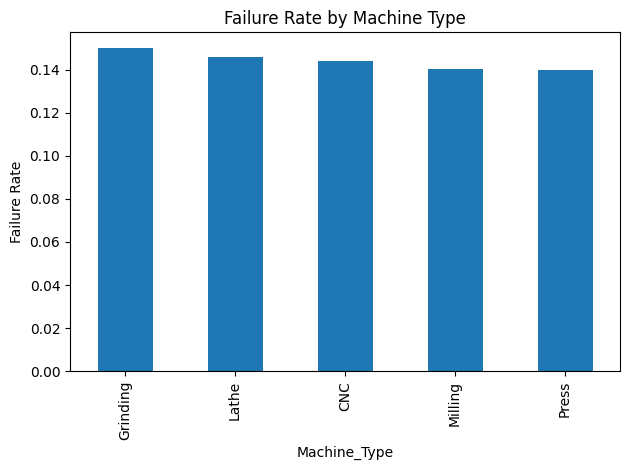

In [10]:
failure_by_machine.plot(
    kind="bar",
    title="Failure Rate by Machine Type",
    ylabel="Failure Rate"
)

plt.tight_layout()
plt.show()

In [11]:
df.groupby("Failure_Next_30_Days")["Vibration_mm_s"].mean()

Failure_Next_30_Days
0    3.937771
1    4.324565
Name: Vibration_mm_s, dtype: float64

In [12]:
df.groupby("Failure_Next_30_Days")["Temperature_C"].mean()

Failure_Next_30_Days
0    69.619587
1    71.865975
Name: Temperature_C, dtype: float64

In [13]:
df.groupby("Failure_Next_30_Days")["Last_Maintenance_Days"].mean()

Failure_Next_30_Days
0    179.575535
1    204.575295
Name: Last_Maintenance_Days, dtype: float64

In [14]:
df.groupby("Failure_Next_30_Days")["Machine_Age_Years"].mean()

Failure_Next_30_Days
0    7.885617
1    8.533657
Name: Machine_Age_Years, dtype: float64

In [15]:
numeric_features = [
    "Machine_Age_Years",
    "Operating_Hours",
    "Temperature_C",
    "Vibration_mm_s",
    "Pressure_bar",
    "Motor_Current_A",
    "Production_Count",
    "Production_Rate",
    "Last_Maintenance_Days",
    "Maintenance_Count",
    "Failure_Count"
]

correlation = (
    df[numeric_features + ["Failure_Next_30_Days"]]
    .corr()["Failure_Next_30_Days"]
    .sort_values(ascending=False)
)

correlation

Failure_Next_30_Days     1.000000
Operating_Hours          0.108743
Vibration_mm_s           0.091290
Last_Maintenance_Days    0.083728
Temperature_C            0.079759
Machine_Age_Years        0.052452
Pressure_bar             0.018504
Failure_Count            0.005921
Motor_Current_A          0.005451
Production_Rate          0.004722
Maintenance_Count        0.000415
Production_Count        -0.001289
Name: Failure_Next_30_Days, dtype: float64